# MetroPT-3 — Exploratory Data Analysis (EDA)

**Input:** `data_raw.csv` (output of Task 1) + the failure table from the dataset PDF.
**Outputs:** `sensor_summary.csv`, `approved_sensors.csv`.

Sections: 1) Load · 2) Overview · 3) Missing values · 4) Time gaps · 4.1) Frozen-logger screening · 5) Analog sensors (distribution + outliers + ranges vs physical expectations) · 6) Digital sensors (+ signal semantics of COMP) · 7) Failures vs readings · 8) Sensor summary and approved list

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

DATA_PATH = Path(os.environ.get("DATA_PATH", r"C:\DEPI\project\data_raw.csv"))
OUT_DIR = Path(os.environ.get("OUT_DIR", r"C:\DEPI\project"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1) Load the data

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
print("Invalid timestamps:", df["timestamp"].isna().sum())

# "Unnamed: 0" is an extra index column (0, 10, 20, ...). Dropped in memory only; data_raw.csv is untouched.
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

df = df.sort_values("timestamp").reset_index(drop=True)
print(df.shape)
df.head()

Invalid timestamps: 0
(1516948, 16)


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


### Sensor definitions (from the dataset PDF)
Analog sensors (1-7) have units; digital sensors (8-15) are 0/1 electrical signals.

In [3]:
ANALOG = {
    "TP2": "bar",              # pressure on the compressor
    "TP3": "bar",              # pressure at the pneumatic panel
    "H1": "bar",               # pressure drop when the cyclonic separator filter discharges
    "DV_pressure": "bar",      # pressure drop when towers discharge; ~0 = compressor under load
    "Reservoirs": "bar",       # downstream reservoir pressure (close to TP3)
    "Oil_temperature": "°C",
    "Motor_current": "A",      # ~0 off, ~4 offloaded, ~7 under load, ~9 starting
}
DIGITAL = {
    "COMP": "0/1",             # air intake valve (active = off or offloaded)
    "DV_eletric": "0/1",       # outlet valve control (active = under load)
    "Towers": "0/1",           # which drying tower is in use
    "MPG": "0/1",              # start under load when pressure < 8.2 bar
    "LPS": "0/1",              # active when pressure < 7 bar
    "Pressure_switch": "0/1",  # discharge in the drying towers
    "Oil_level": "0/1",        # active when oil is BELOW expected level
    "Caudal_impulses": "0/1",  # pulses of air flow from APU to reservoirs
}
A, D = list(ANALOG), list(DIGITAL)

absent = [c for c in A + D if c not in df.columns]
print("Missing expected columns:", absent if absent else "none")

Missing expected columns: none


## 2) Overview

In [4]:
print("Rows x columns:", df.shape)
print("Period:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Duration:", df["timestamp"].max() - df["timestamp"].min())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
df.dtypes

Rows x columns: (1516948, 16)
Period: 2020-02-01 00:00:00 -> 2020-09-01 03:59:50
Duration: 213 days 03:59:50
Duplicate rows: 0
Duplicate timestamps: 0


timestamp          datetime64[us]
TP2                       float64
TP3                       float64
H1                        float64
DV_pressure               float64
Reservoirs                float64
Oil_temperature           float64
Motor_current             float64
COMP                      float64
DV_eletric                float64
Towers                    float64
MPG                       float64
LPS                       float64
Pressure_switch           float64
Oil_level                 float64
Caudal_impulses           float64
dtype: object

## 3) Missing values

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(4),
})
missing

,missing_count,missing_pct
timestamp,0,0.0
TP2,0,0.0
TP3,0,0.0
H1,0,0.0
DV_pressure,0,0.0
Reservoirs,0,0.0
Oil_temperature,0,0.0
Motor_current,0,0.0
COMP,0,0.0
DV_eletric,0,0.0


## 4) Time gaps
The expected sampling interval is the **median** time step (about 10 seconds in this version of the dataset).
A gap is any step larger than 3x the typical interval.

In [6]:
dt = df["timestamp"].diff()
typical = dt.median()
print("Typical sampling interval:", typical)
print("\nMost common steps:")
print(dt.value_counts().head(5))

gap_mask = dt > 3 * typical
gaps = pd.DataFrame({
    "gap_start": df["timestamp"].shift(1)[gap_mask],
    "gap_end": df["timestamp"][gap_mask],
    "gap_length": dt[gap_mask],
}).sort_values("gap_length", ascending=False)

n_missing_readings = int(((gaps["gap_length"] / typical) - 1).sum()) if len(gaps) else 0
print("\nNumber of gaps:", len(gaps))
print("Total time inside gaps:", gaps["gap_length"].sum())
print("Approx. readings missing because of gaps:", n_missing_readings)
gaps.head(15)

Typical sampling interval: 0 days 00:00:10

Most common steps:
timestamp
0 days 00:00:10    1337521
0 days 00:00:09     128277
0 days 00:00:12      38321
0 days 00:00:13       7988
0 days 00:00:11       4471
Name: count, dtype: int64

Number of gaps: 331
Total time inside gaps: 37 days 21:31:03
Approx. readings missing because of gaps: 327095


,gap_start,gap_end,gap_length
618538,2020-04-25 01:10:51,2020-04-27 01:12:49,2 days 00:01:58
1055664,2020-06-27 10:53:07,2020-06-28 23:07:43,1 days 12:14:36
214850,2020-02-28 23:57:08,2020-03-01 04:00:09,1 days 04:03:01
1318888,2020-08-04 07:42:28,2020-08-05 08:23:01,1 days 00:40:33
805415,2020-05-24 00:39:23,2020-05-25 01:14:14,1 days 00:34:51
1126187,2020-07-07 15:24:51,2020-07-08 15:20:51,0 days 23:56:00
1454438,2020-08-22 19:11:44,2020-08-23 18:51:01,0 days 23:39:17
708881,2020-05-10 00:31:17,2020-05-10 22:48:58,0 days 22:17:41
908125,2020-06-07 14:19:39,2020-06-08 11:48:04,0 days 21:28:25
450114,2020-04-01 13:15:40,2020-04-02 09:59:17,0 days 20:43:37


## 4.1) Frozen-logger periods (screening)

A frozen-logger candidate is a stretch where timestamps continue but **all analog sensors** (`A`) remain unchanged across consecutive rows. This is a screening rule, not proof of logger failure: stable operating conditions can also produce repeated values.

The minimum duration below is an initial configurable threshold. Review the detected periods before excluding affected rows from modelling.

In [ ]:
MIN_FROZEN_DURATION = pd.Timedelta(minutes=5)

same_as_previous = df[A].eq(df[A].shift(1)).all(axis=1)
same_as_previous.iloc[0] = False
run_id = same_as_previous.ne(same_as_previous.shift(fill_value=False)).cumsum()
candidate_rows = []
for _, run in df.loc[same_as_previous].groupby(run_id[same_as_previous]):
    first_idx = run.index[0]
    last_idx = run.index[-1]
    start_idx = max(df.index.min(), first_idx - 1)
    start_time = df.loc[start_idx, 'timestamp']
    end_time = df.loc[last_idx, 'timestamp']
    duration = end_time - start_time
    if duration >= MIN_FROZEN_DURATION:
        candidate_rows.append({
            'start_time': start_time,
            'end_time': end_time,
            'duration': duration,
            'duration_seconds': duration.total_seconds(),
            'repeated_steps': int(len(run)),
        })

frozen_periods = pd.DataFrame(candidate_rows, columns=[
    'start_time', 'end_time', 'duration', 'duration_seconds', 'repeated_steps'
])

df['frozen_logger_flag'] = False
for _, period in frozen_periods.iterrows():
    df.loc[df['timestamp'].between(period['start_time'], period['end_time']), 'frozen_logger_flag'] = True

print('Minimum duration:', MIN_FROZEN_DURATION)
print('Candidate frozen-logger periods:', len(frozen_periods))
print('Flagged rows:', int(df['frozen_logger_flag'].sum()))
display(frozen_periods.head(20))
frozen_periods.to_csv(OUT_DIR / 'frozen_logger_periods.csv', index=False)


Minimum duration: 0 days 00:05:00
Candidate frozen-logger periods: 9
Flagged rows: 50864


,start_time,end_time,duration,duration_seconds,repeated_steps
0,2020-03-11 18:29:41,2020-03-11 18:59:14,0 days 00:29:33,1773.0,147
1,2020-04-13 18:29:10,2020-04-13 19:27:16,0 days 00:58:06,3486.0,290
2,2020-04-17 09:20:33,2020-04-18 00:18:07,0 days 14:57:34,53854.0,4469
3,2020-04-20 04:49:07,2020-04-21 01:16:52,0 days 20:27:45,73665.0,6109
4,2020-05-26 09:19:26,2020-05-28 03:16:28,1 days 17:57:02,151022.0,12448
5,2020-06-12 02:01:46,2020-06-12 17:06:06,0 days 15:04:20,54260.0,4501
6,2020-06-22 15:06:11,2020-06-25 05:08:35,2 days 14:02:24,223344.0,18514
7,2020-07-21 13:45:02,2020-07-21 22:03:16,0 days 08:18:14,29894.0,2480
8,2020-07-22 06:43:34,2020-07-22 13:04:24,0 days 06:20:50,22850.0,1897


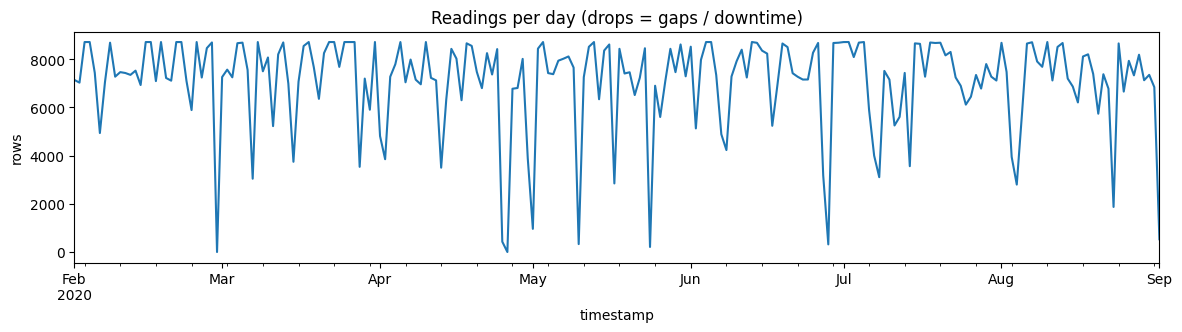

In [8]:
per_day = df.set_index("timestamp").resample("D").size()
ax = per_day.plot(figsize=(14, 3), title="Readings per day (drops = gaps / downtime)")
ax.set_ylabel("rows")
plt.show()

## 5) Analog sensors
### 5.1 Statistics and range

In [9]:
desc = df[A].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[A].skew()
desc["unit"] = pd.Series(ANALOG)
desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,unit
TP2,1516948.0,1.367826,3.250930,-0.032,-0.024,-0.014,-0.012,-0.0100,10.3520,10.676,1.986279,bar
TP3,1516948.0,8.984611,0.639095,0.730,7.876,8.492,8.960,9.4920,10.1400,10.302,-0.877349,bar
H1,1516948.0,7.568155,3.333200,-0.036,-0.024,8.254,8.784,9.3740,10.1140,10.288,-1.764960,bar
DV_pressure,1516948.0,0.055956,0.382402,-0.032,-0.026,-0.022,-0.020,-0.0180,2.1120,9.844,5.720572,bar
Reservoirs,1516948.0,8.985233,0.638307,0.712,7.876,8.494,8.960,9.4920,10.1380,10.300,-0.886154,bar
Oil_temperature,1516948.0,62.644182,6.516261,15.400,48.825,57.775,62.700,67.2500,76.1750,89.050,-0.045791,°C
Motor_current,1516948.0,2.050171,2.302053,0.020,0.035,0.040,0.045,3.8075,6.1875,9.295,0.448561,A


### 5.2 Distributions (plots use a 200k-row random sample for speed; all statistics use the full data)

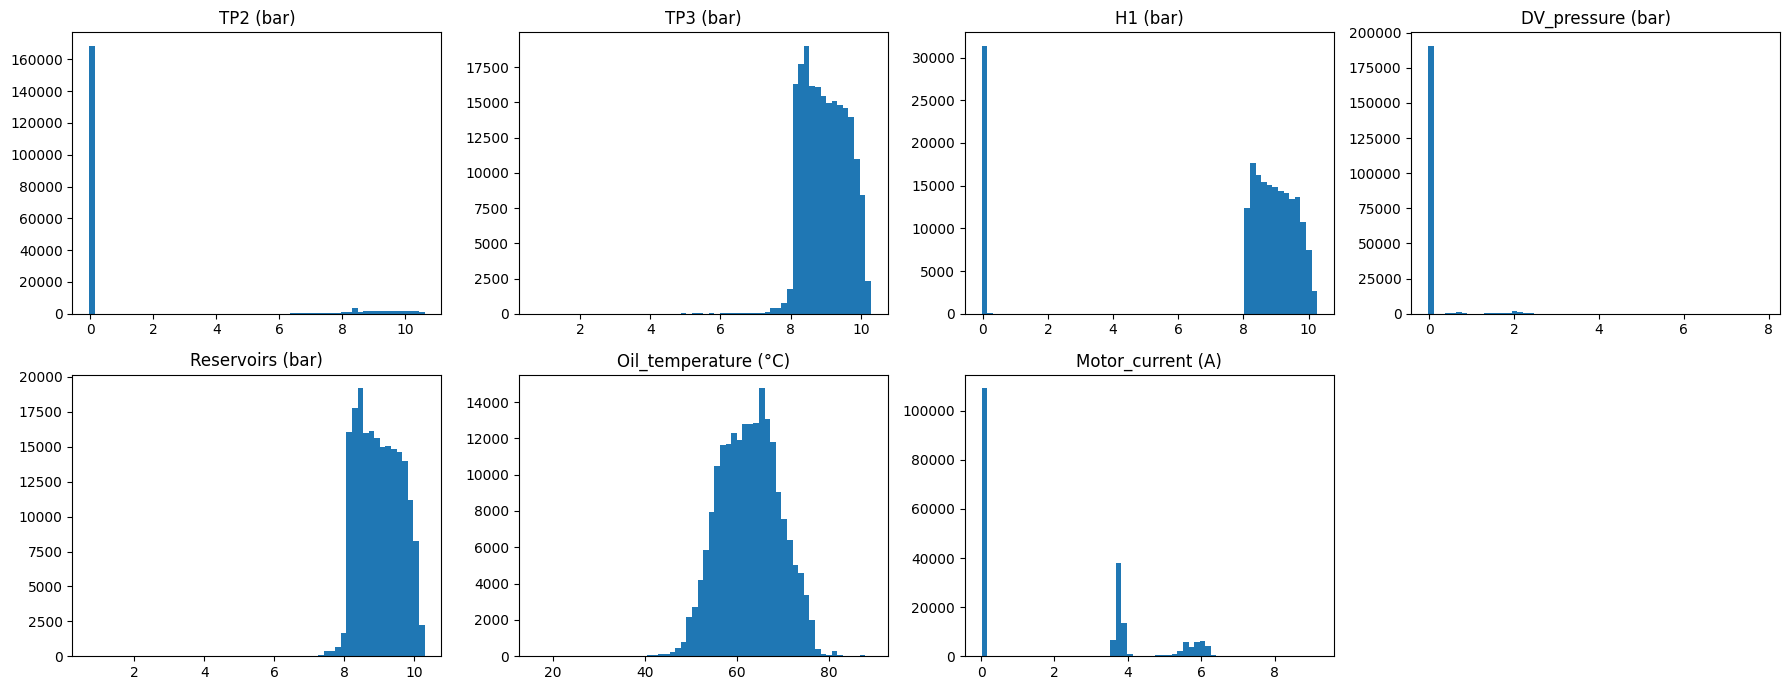

In [10]:
sample = df[A].sample(min(200_000, len(df)), random_state=0)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), A):
    ax.hist(sample[c].dropna(), bins=60)
    ax.set_title(f"{c} ({ANALOG[c]})")
for ax in axes.ravel()[len(A):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

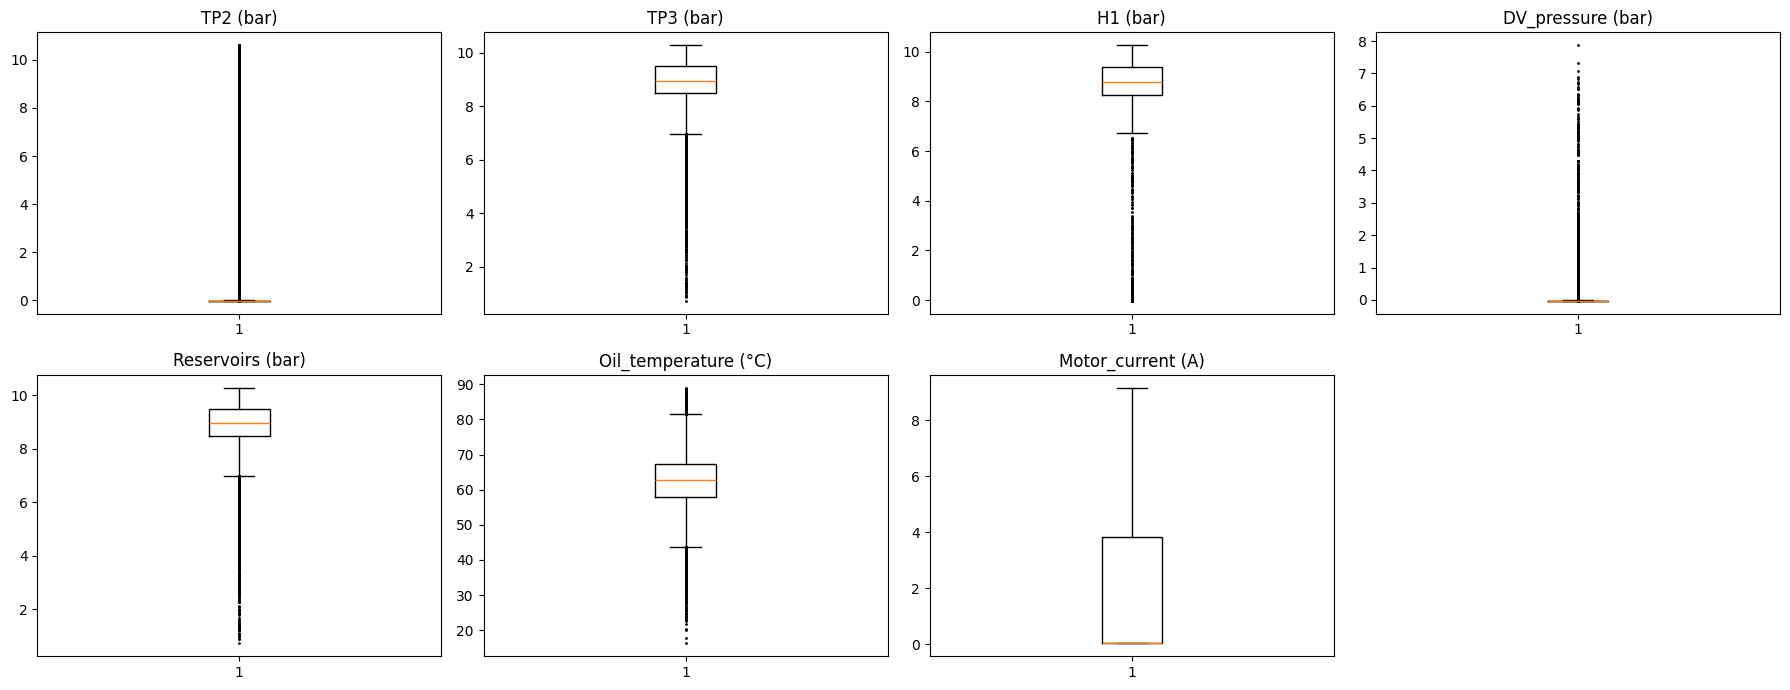

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), A):
    ax.boxplot(sample[c].dropna(), vert=True, showfliers=True, flierprops={"markersize": 1})
    ax.set_title(f"{c} ({ANALOG[c]})")
for ax in axes.ravel()[len(A):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 5.3 Outliers
Two checks:
1. **IQR rule** (1.5 x IQR). Compressor data switches between modes (off / offloaded / under load), so the IQR rule will flag many valid readings. **Do not delete them blindly.**
2. **Physical range check** with assumed plausible bounds (edit `PHYS` if you know the real limits).

In [12]:
q1, q3 = df[A].quantile(.25), df[A].quantile(.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_count = ((df[A] < lower) | (df[A] > upper)).sum()

PHYS = {  # assumed plausible bounds (min, max)
    "TP2": (-0.1, 12), "TP3": (-0.1, 12), "H1": (-0.1, 12),
    "DV_pressure": (-0.1, 12), "Reservoirs": (-0.1, 12),
    "Oil_temperature": (0, 120), "Motor_current": (0, 15),
}
phys_count = pd.Series({
    c: int(((df[c] < PHYS[c][0]) | (df[c] > PHYS[c][1])).sum()) for c in A
})

outliers = pd.DataFrame({
    "iqr_lower": lower, "iqr_upper": upper,
    "outliers_iqr": out_count,
    "outliers_iqr_pct": (out_count / len(df) * 100).round(3),
    "outside_physical_range": phys_count,
    "outside_physical_pct": (phys_count / len(df) * 100).round(3),
})
outliers

,iqr_lower,iqr_upper,outliers_iqr,outliers_iqr_pct,outside_physical_range,outside_physical_pct
TP2,-0.02000,-0.00400,269592,17.772,0,0.0
TP3,6.99200,10.99200,4518,0.298,0,0.0
H1,6.57400,11.05400,241327,15.909,0,0.0
DV_pressure,-0.02800,-0.01200,113111,7.456,0,0.0
Reservoirs,6.99700,10.98900,4526,0.298,0,0.0
Oil_temperature,43.56250,81.46250,5194,0.342,0,0.0
Motor_current,-5.61125,9.45875,0,0.000,0,0.0


### 5.4 Sensor ranges against physical expectations
The physical-range check in 5.3 only catches values that are **impossible** (the hard limits in `PHYS`). This step compares every analog sensor with a second, tighter reference: the range we **expect** from a healthy compressor.

- **Hard limits** (`PHYS`): outside = physically impossible or a sensor error.
- **Normal operating band** (`EXPECTED`): outside = physically possible but unusual (cold start, pressure loss, leak), so it is flagged for **review, not deleted**.

The bands come from the sensor definitions above (LPS is active below 7 bar, MPG starts under load below 8.2 bar, motor current is ~0 / ~4 / ~7 / ~9 A for off / offloaded / loaded / starting). They are **starting assumptions**: edit `EXPECTED` if the dataset PDF or the maintenance team gives different limits. Readings of about -0.03 bar are treated as sensor zero-offset, not as real negative pressure.

Two cross-checks follow the table: `Reservoirs` should follow `TP3` (same pressure, downstream), and the share of `TP3` below 7 bar should match how often `LPS` is active.

In [ ]:
REVIEW_PCT = 1.0  # more than this % outside the operating band -> "review"

EXPECTED = {  # sensor: (operating_min, operating_max, what we expect physically)
    "TP2":             (-0.05, 11.0, "~0 bar when off/offloaded; rises to line pressure under load"),
    "TP3":             (7.0, 10.5,   "panel pressure; LPS activates below 7 bar"),
    "H1":              (-0.05, 11.0, "near line pressure; drops toward 0 at separator discharge"),
    "DV_pressure":     (-0.05, 10.5, "~0 under load; spikes when the towers discharge"),
    "Reservoirs":      (7.0, 10.5,   "follows TP3"),
    "Oil_temperature": (40.0, 85.0,  "warmed-up compressor oil"),
    "Motor_current":   (0.0, 10.0,   "~0 off, ~4 offloaded, ~7 loaded, ~9 starting"),
}

rows = []
for c in A:
    s = df[c]
    hard_min, hard_max = PHYS[c]
    op_min, op_max, note = EXPECTED[c]
    below_op, above_op = int((s < op_min).sum()), int((s > op_max).sum())
    pct_op = round((below_op + above_op) / len(s) * 100, 3)
    hard = int(((s < hard_min) | (s > hard_max)).sum())
    if hard:
        verdict = "violates physical limits"
    elif pct_op > REVIEW_PCT:
        verdict = "review: often outside operating band"
    elif pct_op > 0:
        verdict = "minor excursions"
    else:
        verdict = "within expectations"
    rows.append({
        "sensor": c, "unit": ANALOG[c],
        "obs_min": s.min(), "obs_p1": desc.loc[c, "1%"],
        "obs_p99": desc.loc[c, "99%"], "obs_max": s.max(),
        "expected_min": op_min, "expected_max": op_max,
        "below_band": below_op, "above_band": above_op,
        "pct_outside_band": pct_op, "hard_violations": hard,
        "verdict": verdict, "expectation": note,
    })
ranges = pd.DataFrame(rows).set_index("sensor")

# When do the excursions happen? (top days per sensor)
for c in ranges.index[ranges["pct_outside_band"] > 0]:
    lo, hi = EXPECTED[c][:2]
    m = (df[c] < lo) | (df[c] > hi)
    print(f"{c}: {int(m.sum())} rows outside [{lo}, {hi}]; most affected days:")
    print(df.loc[m, "timestamp"].dt.date.value_counts().head(5).to_string(), "\n")

# Cross-checks between related sensors
gap = (df["TP3"] - df["Reservoirs"]).abs()
print(f"|TP3 - Reservoirs|: median {gap.median():.3f} bar, 99th pct {gap.quantile(.99):.3f} bar, max {gap.max():.3f} bar")
print(f"TP3 < 7 bar: {(df['TP3'] < 7).mean() * 100:.3f}% of rows | LPS active: {df['LPS'].mean() * 100:.3f}%")
ranges

## 6) Digital sensors

In [13]:
rows = []
for c in D:
    s = df[c]
    nun = s.nunique(dropna=True)
    rows.append({
        "sensor": c,
        "n_unique": nun,
        "values": sorted(s.dropna().unique().tolist()) if nun <= 5 else "many",
        "pct_active (value=1)": round(s.mean() * 100, 3),
        "state_changes": int((s.diff().fillna(0) != 0).sum()),
    })
digital_summary = pd.DataFrame(rows).set_index("sensor")
digital_summary

,n_unique,values,pct_active (value=1),state_changes
sensor,,,,
COMP,2,"[0.0, 1.0]",83.696,33846
DV_eletric,2,"[0.0, 1.0]",16.061,31448
Towers,2,"[0.0, 1.0]",91.985,64580
MPG,2,"[0.0, 1.0]",83.266,31012
LPS,2,"[0.0, 1.0]",0.342,254
Pressure_switch,2,"[0.0, 1.0]",99.144,23628
Oil_level,2,"[0.0, 1.0]",90.416,15336
Caudal_impulses,2,"[0.0, 1.0]",93.711,15292


### 6.1 Signal semantics: which COMP state means the compressor is producing air
`COMP` is easy to misread. The intuitive reading is *1 = on / running*. According to the dataset PDF it is the **air intake valve**, and it is **active when the compressor is off or offloaded**, so the polarity is the **opposite** of that intuition:

| COMP | Intake valve | Compressor state |
| --- | --- | --- |
| **1** (active) | closed | off or offloaded, **not** producing air |
| **0** (inactive) | open | under load, **producing air** |

Evidence already visible in this notebook:
- `COMP` is active in 83.7% of rows. The inactive share (16.3%) matches `DV_eletric` being active (16.06%), and `DV_eletric` = active means *under load*.
- In the failure windows (air leaks make the compressor load almost continuously) `COMP` falls to ~0.4% active while `DV_eletric` rises to ~99.5% and `Motor_current` goes from 1.98 A to 5.53 A. The -99.5% change for `COMP` in Section 7 therefore means the compressor was **loaded nearly all the time**, not switched off.
- `MPG` moves together with `COMP` (same failure-window mean, 0.0044), so the same caution applies to it.

The cell below confirms the polarity on the full data and creates `producing_air` (True when `COMP == 0`). Use this column, not raw `COMP`, for duty-cycle and load features. Also note that `pct_active` in Section 6 is **not** "% of time running": for `COMP` it is the share of time the compressor was *not* producing air.

In [ ]:
PRODUCING_AIR_VALUE = 0   # COMP is active (1) when off/offloaded, so 0 = intake open = producing air
MOTOR_OFF_A = 0.5         # below this the motor is considered stopped (~0 A when off)

df["_motor_stopped"] = df["Motor_current"] < MOTOR_OFF_A
by_comp = df.groupby("COMP").agg(
    rows=("COMP", "size"),
    motor_current_mean=("Motor_current", "mean"),
    tp2_mean=("TP2", "mean"),
    dv_eletric_active=("DV_eletric", "mean"),
    motor_stopped_pct=("_motor_stopped", "mean"),
)
by_comp["share_pct"] = (by_comp["rows"] / len(df) * 100).round(2)
by_comp["motor_stopped_pct"] = (by_comp["motor_stopped_pct"] * 100).round(2)
df = df.drop(columns="_motor_stopped")
display(by_comp.round(3))

# The state with the higher compressor pressure (TP2) is the one where air is produced.
air_state = by_comp["tp2_mean"].idxmax()
if air_state == PRODUCING_AIR_VALUE:
    print(f"Confirmed: COMP == {PRODUCING_AIR_VALUE} is the producing-air state (higher TP2 and motor current than COMP == 1).")
else:
    print(f"WARNING: data suggests COMP == {air_state} is the producing-air state. Check PRODUCING_AIR_VALUE.")

print(f"COMP and DV_eletric differ in {(df['COMP'] != df['DV_eletric']).mean() * 100:.2f}% of rows (mirror images)")
print(f"COMP and MPG are equal in {(df['COMP'] == df['MPG']).mean() * 100:.2f}% of rows")

df["producing_air"] = df["COMP"].eq(PRODUCING_AIR_VALUE)
print(f"Share of time producing air: {df['producing_air'].mean() * 100:.2f}%")

## 7) Failures vs sensor readings
The dataset is unlabeled; the failure windows below come from the PDF (same as `failure_log.csv`).

In [14]:
failures = pd.DataFrame({
    "failure_id": [1, 2, 3, 4],
    "start_time": pd.to_datetime(["2020-04-18 00:00", "2020-05-29 23:30", "2020-06-05 10:00", "2020-07-15 14:30"]),
    "end_time":   pd.to_datetime(["2020-04-18 23:59", "2020-05-30 06:00", "2020-06-07 14:30", "2020-07-15 19:00"]),
    "failure_type": "Air leak",
})

df["in_failure"] = False
for _, r in failures.iterrows():
    df.loc[df["timestamp"].between(r["start_time"], r["end_time"]), "in_failure"] = True

print("Rows inside failure windows:", int(df["in_failure"].sum()),
      f"({df['in_failure'].mean() * 100:.2f}%)")

cmp_ = df.groupby("in_failure")[A + D].mean().T
cmp_.columns = ["normal_mean", "failure_mean"]
cmp_["change_pct"] = ((cmp_["failure_mean"] - cmp_["normal_mean"]) / cmp_["normal_mean"].replace(0, np.nan) * 100).round(2)
cmp_

Rows inside failure windows: 29954 (1.97%)


,normal_mean,failure_mean,change_pct
TP2,1.231905,8.115287,558.76
TP3,8.998642,8.288059,-7.90
H1,7.719849,0.037668,-99.51
DV_pressure,0.019619,1.859813,9379.51
Reservoirs,8.999247,8.289548,-7.89
Oil_temperature,62.383231,75.598441,21.18
Motor_current,1.980028,5.532224,179.40
COMP,0.853727,0.004440,-99.48
DV_eletric,0.143805,0.994892,591.83
Towers,0.928266,0.501970,-45.92


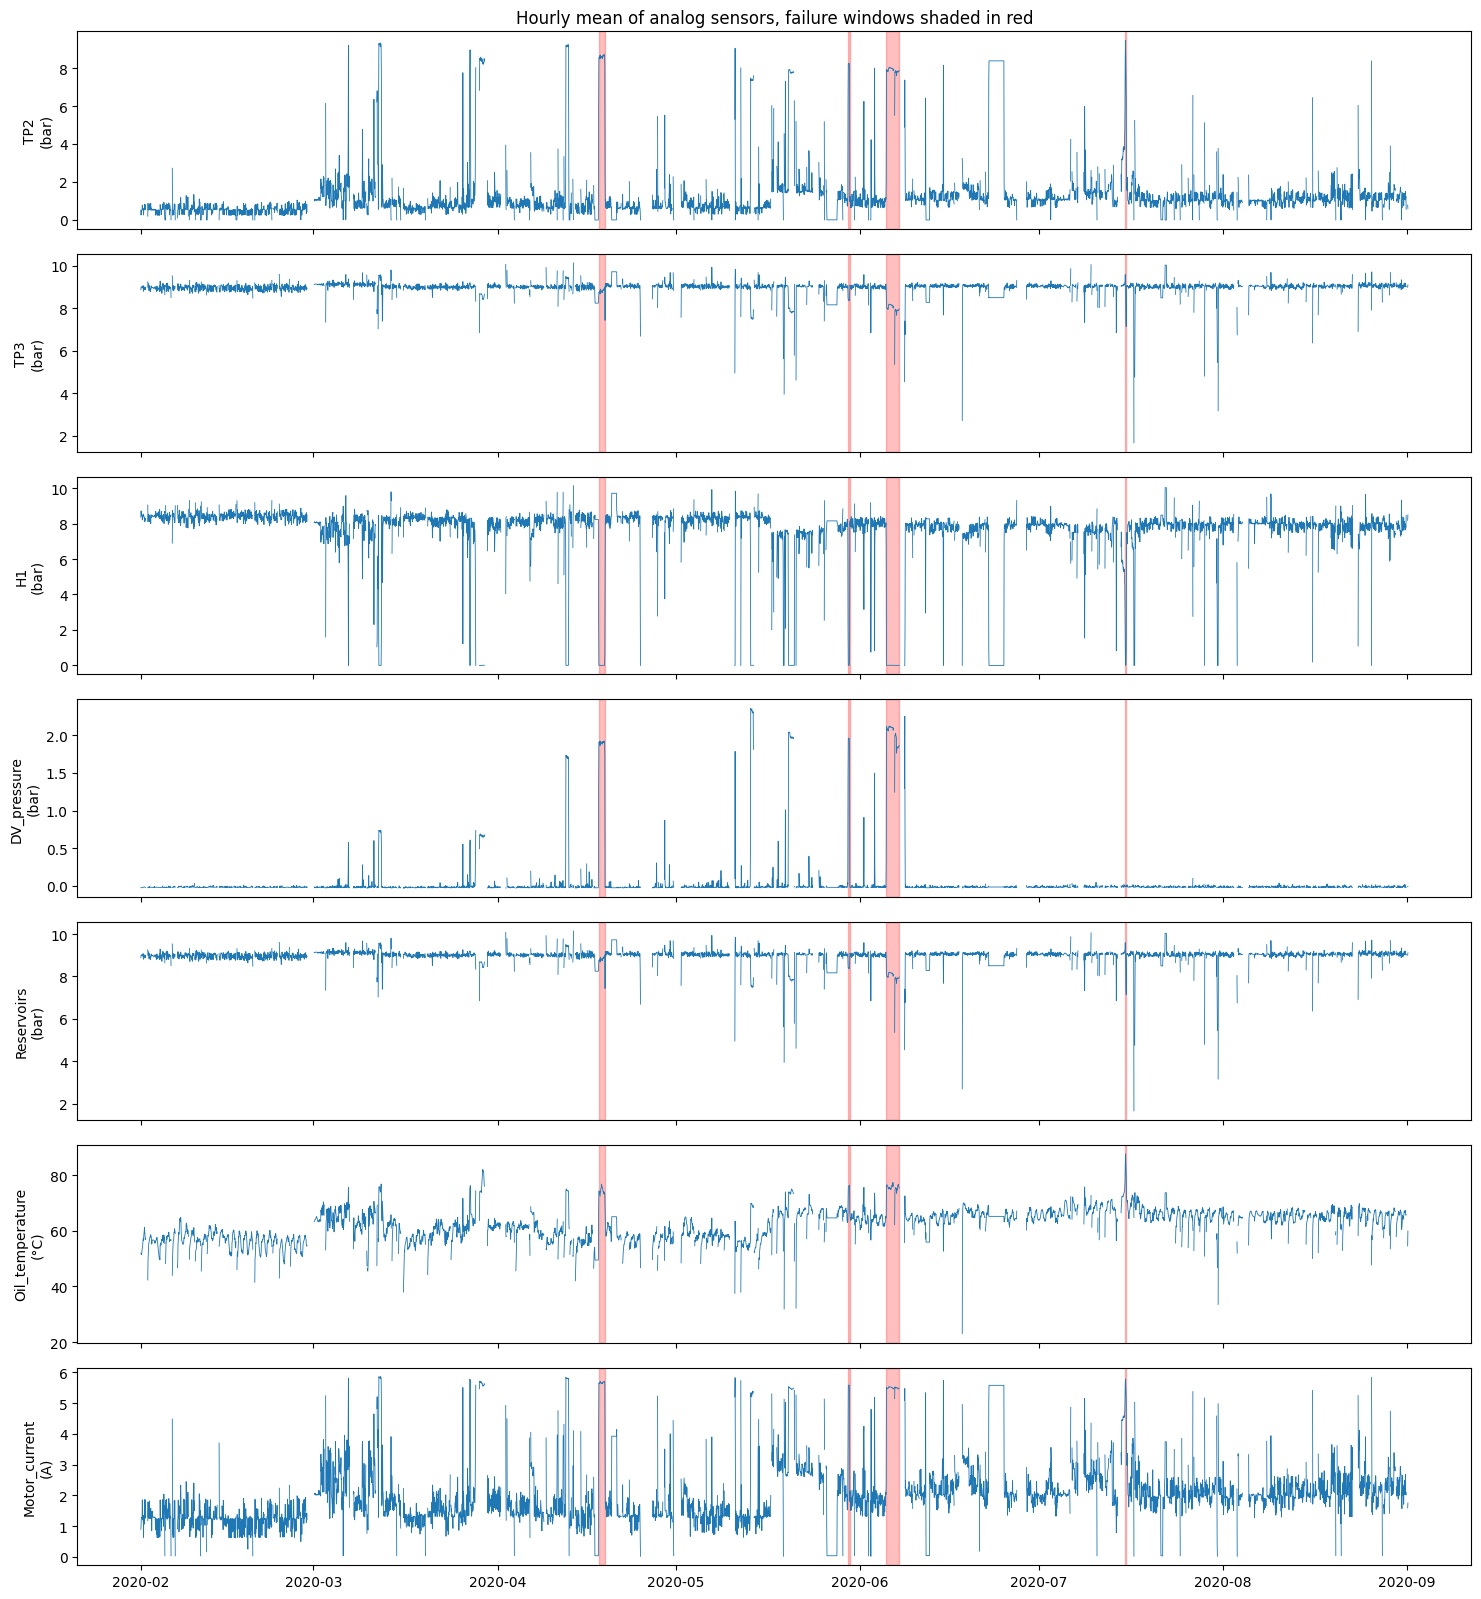

In [15]:
hourly = df.set_index("timestamp")[A].resample("1h").mean()

fig, axes = plt.subplots(len(A), 1, figsize=(15, 2.3 * len(A)), sharex=True)
for ax, c in zip(axes, A):
    ax.plot(hourly.index, hourly[c], lw=0.6)
    for _, r in failures.iterrows():
        ax.axvspan(r["start_time"], r["end_time"], color="red", alpha=0.25)
    ax.set_ylabel(f"{c}\n({ANALOG[c]})")
axes[0].set_title("Hourly mean of analog sensors, failure windows shaded in red")
plt.tight_layout()
plt.show()

## 8) Sensor summary and approved sensors
**Approval rules** (edit the thresholds below if your supervisor asks for different ones):
- missing values <= `MAX_MISSING_PCT`
- not constant (more than one distinct value)
- values outside the physical range <= `MAX_PHYSICAL_PCT` (analog only)

In [16]:
MAX_MISSING_PCT = 5.0
MAX_PHYSICAL_PCT = 5.0

rows = []
for c in A + D:
    s = df[c]
    is_analog = c in ANALOG
    row = {
        "sensor": c,
        "type": "analog" if is_analog else "digital",
        "unit": ANALOG.get(c, DIGITAL.get(c)),
        "count": int(s.count()),
        "missing_pct": round(s.isna().mean() * 100, 4),
        "min": s.min(), "max": s.max(),
        "mean": s.mean(), "std": s.std(), "median": s.median(),
        "n_unique": int(s.nunique()),
    }
    if is_analog:
        row.update({
            "q1": q1[c], "q3": q3[c],
            "outliers_iqr": int(out_count[c]),
            "outliers_iqr_pct": float(outliers.loc[c, "outliers_iqr_pct"]),
            "outside_physical_pct": float(outliers.loc[c, "outside_physical_pct"]),
            "pct_active": np.nan,
        })
    else:
        row.update({
            "q1": np.nan, "q3": np.nan,
            "outliers_iqr": np.nan, "outliers_iqr_pct": np.nan,
            "outside_physical_pct": np.nan,
            "pct_active": round(s.mean() * 100, 3),
        })
    rows.append(row)

summary = pd.DataFrame(rows)


def decide(r):
    reasons = []
    if r["missing_pct"] > MAX_MISSING_PCT:
        reasons.append(f"missing > {MAX_MISSING_PCT}%")
    if r["n_unique"] <= 1:
        reasons.append("constant value")
    if pd.notna(r["outside_physical_pct"]) and r["outside_physical_pct"] > MAX_PHYSICAL_PCT:
        reasons.append(f"outside physical range > {MAX_PHYSICAL_PCT}%")
    return pd.Series({
        "status": "approved" if not reasons else "rejected",
        "reason": "; ".join(reasons),
    })


summary = pd.concat([summary, summary.apply(decide, axis=1)], axis=1)
summary.to_csv(OUT_DIR / "sensor_summary.csv", index=False)
summary

,sensor,type,unit,count,missing_pct,min,max,mean,std,median,n_unique,q1,q3,outliers_iqr,outliers_iqr_pct,outside_physical_pct,pct_active,status,reason
0,TP2,analog,bar,1516948,0.0,-0.032,10.676,1.367826,3.250930,-0.012,5257,-0.014,-0.0100,269592.0,17.772,0.0,NaN,approved,
1,TP3,analog,bar,1516948,0.0,0.730,10.302,8.984611,0.639095,8.960,3683,8.492,9.4920,4518.0,0.298,0.0,NaN,approved,
2,H1,analog,bar,1516948,0.0,-0.036,10.288,7.568155,3.333200,8.784,2665,8.254,9.3740,241327.0,15.909,0.0,NaN,approved,
3,DV_pressure,analog,bar,1516948,0.0,-0.032,9.844,0.055956,0.382402,-0.020,2257,-0.022,-0.0180,113111.0,7.456,0.0,NaN,approved,
4,Reservoirs,analog,bar,1516948,0.0,0.712,10.300,8.985233,0.638307,8.960,3682,8.494,9.4920,4526.0,0.298,0.0,NaN,approved,
5,Oil_temperature,analog,°C,1516948,0.0,15.400,89.050,62.644182,6.516261,62.700,2462,57.775,67.2500,5194.0,0.342,0.0,NaN,approved,
6,Motor_current,analog,A,1516948,0.0,0.020,9.295,2.050171,2.302053,0.045,1809,0.040,3.8075,0.0,0.000,0.0,NaN,approved,
7,COMP,digital,0/1,1516948,0.0,0.000,1.000,0.836957,0.369405,1.000,2,NaN,NaN,NaN,NaN,NaN,83.696,approved,
8,DV_eletric,digital,0/1,1516948,0.0,0.000,1.000,0.160611,0.367172,0.000,2,NaN,NaN,NaN,NaN,NaN,16.061,approved,
9,Towers,digital,0/1,1516948,0.0,0.000,1.000,0.919848,0.271528,1.000,2,NaN,NaN,NaN,NaN,NaN,91.985,approved,


In [17]:
approved = summary.loc[summary["status"] == "approved", ["sensor", "type", "unit"]]
approved.to_csv(OUT_DIR / "approved_sensors.csv", index=False)

print(f"Approved: {len(approved)} of {len(summary)} sensors")
print(approved["sensor"].tolist())
rejected = summary.loc[summary["status"] == "rejected", ["sensor", "reason"]]
print("\nRejected:")
print(rejected if len(rejected) else "none")

Approved: 15 of 15 sensors
['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

Rejected:
none


## Notes and findings (fill in after running)
- Sampling interval and gaps: ...
- Sensors with unusual ranges or skew: ...
- Sensor ranges vs physical expectations (5.4): ...
- Signal semantics: COMP = 1 means off/offloaded (NOT producing air); COMP = 0 means producing air. Use `producing_air` instead of raw `COMP`: ...
- Sensors that changed most during failure windows: ...
- Final approved sensor list: ...